# CODE 1.2: Find Photos of the Same Gum

> **Goal:** find photos that show the **same piece of gum twice**. If one photo of a gum is in train and the other in test, the model has already seen that gum before the test. The test then looks easier than it really is. This is called **data leakage**.
>
> - **Input:** the photo list and the photos in `data/raw/chewinggum/`
> - **Output:** `splits/same_gum_photos.csv`: the photos that show the same gum, and which of them we leave out. Notebook 1.3 uses this file when it splits the data.
>
> Notebook 1.1 showed that no file is an exact copy of another. But when a gum is photographed twice, the two files are different: the gum moves a little and the light changes slightly. So here we compare what is **in** the photos, not the files.

### The Idea in Short

> Every gum has its own tiny bumps, dents and marks on its surface, like a fingerprint. Two different gums never have the same pattern. So:
>
> 1. **Find the gum** in each photo (Step 1).
> 2. **Keep only the fine texture** of its surface, without light and shadow (Step 2).
> 3. **Quick search:** compare all photos with each other in a fast, rough way, and keep the most similar pairs (Step 3).
> 4. **Careful comparison:** line up each kept pair (move and turn) and measure how well the textures match (Step 4).
> 5. **Choose a limit** for "same gum" (Step 5) and **look at the pairs** with our own eyes (Step 6).
> 6. **Decide which photos to leave out** and save the list (Step 7).

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths.
> - `numpy`: works with numbers and pixels.
> - `pandas`: works with tables.
> - `matplotlib`: draws the figures.
> - `PIL` (Pillow): opens photos.
> - `scipy.ndimage`: blurs, turns and measures pictures.
> - `scipy.sparse` and `scipy.sparse.csgraph`: join pairs that share a photo into one group (Step 7).
> - `tqdm`: shows a progress bar while the code goes through many photos.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from tqdm import tqdm

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `ROOT_DIR`: the main project folder.
> - `RAW_DIR`: the original data. We only read from it.
> - `GUM_DIR`: the chewing gum photos, masks and photo list.
> - `SPLITS_DIR`: where our split files are saved.
> - `SAME_GUM_FILE`: the file this notebook saves.
>
> If the data is missing, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

RAW_DIR = os.path.join(ROOT_DIR, "data", "raw")
GUM_DIR = os.path.join(RAW_DIR, "chewinggum")
SPLITS_DIR = os.path.join(ROOT_DIR, "splits")
SAME_GUM_FILE = os.path.join(SPLITS_DIR, "same_gum_photos.csv")

if not os.path.exists(os.path.join(GUM_DIR, "image_anno.csv")):
    raise FileNotFoundError("Data not found. Copy the 'chewinggum' folder into data/raw/ (see README).")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> - `FIND_SCALE`: to find the gum quickly, the photo is first made 4 times smaller.
> - `GUM_BRIGHTNESS`: pixels brighter than this belong to the gum (the gum is white, the mat is dark). Step 1 shows why 120 works.
> - `INNER_MARGIN`: we cut away 8% of the gum on the left and right and 10% at the top and bottom, and only compare the inside. Every gum has the same rounded outline, so with the outline all photos would look alike.
> - `TEXTURE_SIZE`: the inside of the gum is resized to 400 x 200 pixels (width x height), so all photos can be compared pixel by pixel.
> - `BLUR_SIGMA`: how strong the blur is that removes light and shadow (Step 2). A bigger number means a stronger blur.
> - `QUICK_BLOCK`: for the quick search, the texture is made 4 times smaller by taking the average of each 4 x 4 block of pixels.
> - `TOP_K`: in the quick search, each photo keeps its 5 most similar photos for the careful comparison.
> - `ANGLES`: the gum can be turned a little between two photos, so the careful comparison tries turns from -3 to +3 degrees.
> - `EDGE`: after a texture is moved to line it up, the outer 15 pixels are not used, because they were pushed in from the other side.

In [3]:
FIND_SCALE = 4
GUM_BRIGHTNESS = 120
INNER_MARGIN = (0.08, 0.10)
TEXTURE_SIZE = (400, 200)
BLUR_SIGMA = 4
QUICK_BLOCK = 4
TOP_K = 5
ANGLES = [-3, -2, -1, 0, 1, 2, 3]
EDGE = 15

## Functions

### Short Photo Name

> `short_name()` shortens a photo path for tables and titles, for example `chewinggum/Data/Images/Normal/112.JPG` becomes `Normal/112.JPG`.

In [4]:
def short_name(rel_path):
    return rel_path.split("Images/")[-1]

### Find the Gum

> `find_gum_box()` returns the box around the gum as (left, top, right, bottom), in pixels of the full photo:
>
> 1. make the gray photo `scale` times smaller, so it is fast,
> 2. smooth it a little and mark every pixel brighter than `brightness`,
> 3. keep the biggest group of bright pixels that touch each other (the gum) and take the box around it.

In [5]:
def find_gum_box(gray, scale, brightness):
    small = gray.resize((gray.width // scale, gray.height // scale), Image.BILINEAR)
    bright = ndimage.uniform_filter(np.asarray(small, dtype=float), 3) > brightness
    pieces, n_pieces = ndimage.label(bright)
    sizes = np.bincount(pieces.ravel())
    sizes[0] = 0   
    rows, cols = np.nonzero(pieces == sizes.argmax())
    return cols.min() * scale, rows.min() * scale, (cols.max() + 1) * scale, (rows.max() + 1) * scale

### Cut Away the Edge of the Gum

> `inner_box()` makes a box smaller on every side. `margin` gives how much to cut, as a share of the box width (left and right) and height (top and bottom).

In [6]:
def inner_box(box, margin):
    left, top, right, bottom = box
    width, height = right - left, bottom - top
    return (int(left + margin[0] * width), int(top + margin[1] * height),
            int(right - margin[0] * width), int(bottom - margin[1] * height))

### Make the Texture

> `gum_texture()` turns the inside of the gum into its fine texture:
>
> 1. cut the `box` out of the gray photo and resize it to `size`,
> 2. subtract a blurred copy. Light and shadow change slowly, so the blur keeps them and the subtraction removes them. What is left are the small details: bumps, dents and marks,
> 3. blur the result very lightly (sigma 1) to remove camera noise,
> 4. scale the numbers so their average is 0 and their spread is 1. Then a brighter and a darker photo can be compared fairly.

In [7]:
def gum_texture(gray, box, size, blur_sigma):
    inside = np.asarray(gray.crop(box).resize(size, Image.BILINEAR), dtype=float)
    texture = inside - ndimage.gaussian_filter(inside, blur_sigma)
    texture = ndimage.gaussian_filter(texture, 1)
    return (texture - texture.mean()) / texture.std()

### Line Up and Compare Two Textures

> `similarity()` compares two textures and returns a score:
>
> - **about 0:** the two patterns have nothing to do with each other (two different gums),
> - **close to 1:** the patterns match (the same gum).
>
> The gum can move and turn a little between two photos. So for every angle in `angles`:
>
> 1. turn texture `b` by that angle,
> 2. find the shift that lines `b` up best with `a`. This uses **phase correlation**: a fast way to find how far one picture is moved compared to another, with the Fourier transform (`np.fft`),
> 3. move `b` by that shift and measure how well the two match with the **correlation**, leaving out `edge` pixels at the border.
>
> The best match over all angles is the score.

In [8]:
def similarity(a, b, angles, edge):
    fft_a = np.fft.fft2(a)
    best = -1.0
    for angle in angles:
        turned = ndimage.rotate(b, angle, reshape=False, order=1, mode="nearest") if angle != 0 else b
        cross = fft_a * np.conj(np.fft.fft2(turned))
        peak = np.fft.ifft2(cross / (np.abs(cross) + 1e-9)).real
        shift = np.unravel_index(peak.argmax(), peak.shape)
        moved = np.roll(turned, shift, axis=(0, 1))
        inner_a = a[edge:-edge, edge:-edge].ravel()
        inner_b = moved[edge:-edge, edge:-edge].ravel()
        best = max(best, float(np.corrcoef(inner_a, inner_b)[0, 1]))
    return best

### Rank in the Quick Search

> `quick_rank()` tells how photo `j` ranked among all other photos when photo `i` looked for its most similar photos in the quick search. Rank 1 means `j` was the most similar of all.

In [9]:
def quick_rank(quick, i, j):
    return int((quick[i] > quick[i, j]).sum()) + 1

### Show Photo Pairs

> `show_pairs()` shows pairs of photos side by side, cut around the gum, with their score in the title.

In [10]:
def show_pairs(pairs, title, scale, brightness):
    fig, axes = plt.subplots(len(pairs), 2, figsize=(12, 3.4 * len(pairs)), squeeze=False, layout="constrained")
    for row, (_, pair) in enumerate(pairs.iterrows()):
        for col, rel_path in enumerate([pair["photo_a"], pair["photo_b"]]):
            img = Image.open(os.path.join(RAW_DIR, rel_path)).convert("RGB")
            left, top, right, bottom = find_gum_box(img.convert("L"), scale=scale, brightness=brightness)
            axes[row, col].imshow(img.crop((left - 25, top - 25, right + 25, bottom + 25)))
            axes[row, col].set_title(f"{short_name(rel_path)}   (score {pair['score']:.2f})")
            axes[row, col].axis("off")
    fig.suptitle(title, fontsize=14)
    plt.show()

## Load Data

### Load the Photo List

> The same photo list as in notebook 1.1. `is_defect` is `True` for a defect photo.

In [11]:
photos = pd.read_csv(os.path.join(GUM_DIR, "image_anno.csv")).fillna("")
photos["is_defect"] = photos["label"] != "normal"

n_photos = len(photos)
print(f"Photos: {n_photos} ({(~photos['is_defect']).sum()} normal, {photos['is_defect'].sum()} defect)")

Photos: 603 (503 normal, 100 defect)


## Step 1: Find the Gum

### Bright Gum, Dark Mat

> Pixel brightness goes from 0 (black) to 255 (white).
>
> - **Left:** how many pixels of one photo have each brightness. The pixels form two hills: the dark mat on the left and the white gum on the right. The red line is `GUM_BRIGHTNESS`. It lies between the two hills, so it separates gum from mat.
> - **Right:** the same photo. Yellow: the box that `find_gum_box()` finds. Cyan: the inside of the gum that we compare (`INNER_MARGIN`).

Photo: Normal/000.JPG
Pixels darker than 120: 80% | brighter: 20%
Gum box (left, top, right, bottom): (300, 476, 1068, 888)


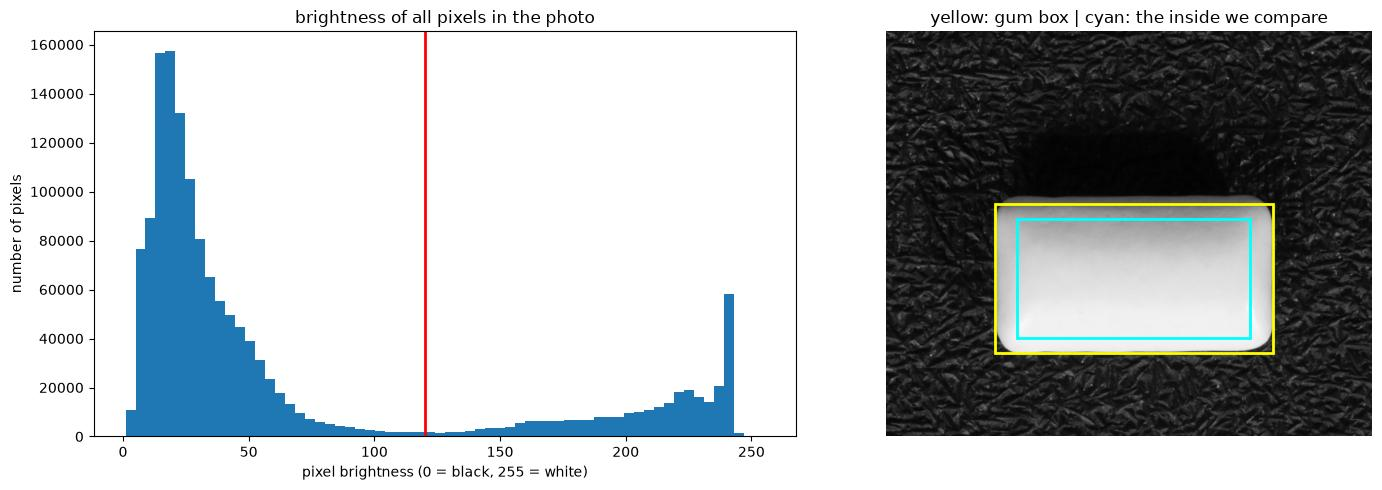

In [12]:
example = photos.iloc[0]
gray = Image.open(os.path.join(RAW_DIR, example["image"])).convert("L")
values = np.asarray(gray).ravel()
gum_box = find_gum_box(gray, scale=FIND_SCALE, brightness=GUM_BRIGHTNESS)
inside = inner_box(gum_box, margin=INNER_MARGIN)
print(f"Photo: {short_name(example['image'])}")
print(f"Pixels darker than {GUM_BRIGHTNESS}: {(values <= GUM_BRIGHTNESS).mean():.0%} | brighter: {(values > GUM_BRIGHTNESS).mean():.0%}")
print("Gum box (left, top, right, bottom):", tuple(int(v) for v in gum_box))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(values, bins=64)
axes[0].axvline(GUM_BRIGHTNESS, color="red", linewidth=2)
axes[0].set_xlabel("pixel brightness (0 = black, 255 = white)")
axes[0].set_ylabel("number of pixels")
axes[0].set_title("brightness of all pixels in the photo")
axes[1].imshow(gray, cmap="gray")
for (left, top, right, bottom), color in [(gum_box, "yellow"), (inside, "cyan")]:
    axes[1].add_patch(Rectangle((left, top), right - left, bottom - top, fill=False, edgecolor=color, linewidth=2))
axes[1].set_title("yellow: gum box | cyan: the inside we compare")
axes[1].axis("off")
plt.tight_layout()
plt.show()

### Is the Gum Found in Every Photo?

> We find the gum box in all photos. Every gum has about the same size, so if the gum is found correctly, the box width and height hardly change. A box that is much smaller or bigger than the others would mean that something else was found.

In [13]:
boxes = []
for rel_path in tqdm(photos["image"], desc="Finding the gum in each photo"):
    boxes.append(find_gum_box(Image.open(os.path.join(RAW_DIR, rel_path)).convert("L"),
                                scale=FIND_SCALE, brightness=GUM_BRIGHTNESS))
box_table = pd.DataFrame(boxes, columns=["left", "top", "right", "bottom"])
box_table["width"] = box_table["right"] - box_table["left"]
box_table["height"] = box_table["bottom"] - box_table["top"]
print(box_table[["width", "height"]].describe().round(1).to_string())

Finding the gum in each photo: 100%|██████████| 603/603 [00:06<00:00, 96.63it/s] 

       width  height
count  603.0   603.0
mean   771.7   418.0
std      8.1    12.0
min    736.0   388.0
25%    768.0   408.0
50%    772.0   416.0
75%    776.0   424.0
max    804.0   456.0


> **What we see:** in all 603 photos the gum box is on average 771.7 x 418.0 pixels. The narrowest box is 736 pixels wide and the widest 804, so no box is far off. The gum is found in every photo.

## Step 2: Keep Only the Fine Texture

### From Photo to Texture

> The three steps of `gum_texture()` on the photo from Step 1:
>
> 1. **the inside of the gum**, in gray and resized to `TEXTURE_SIZE`,
> 2. **the blurred copy**: only light and shadow are left,
> 3. **the texture** = 1 minus 2 (and lightly smoothed). Only the small details are left. Gray is "nothing special", dark and light spots are bumps and marks.

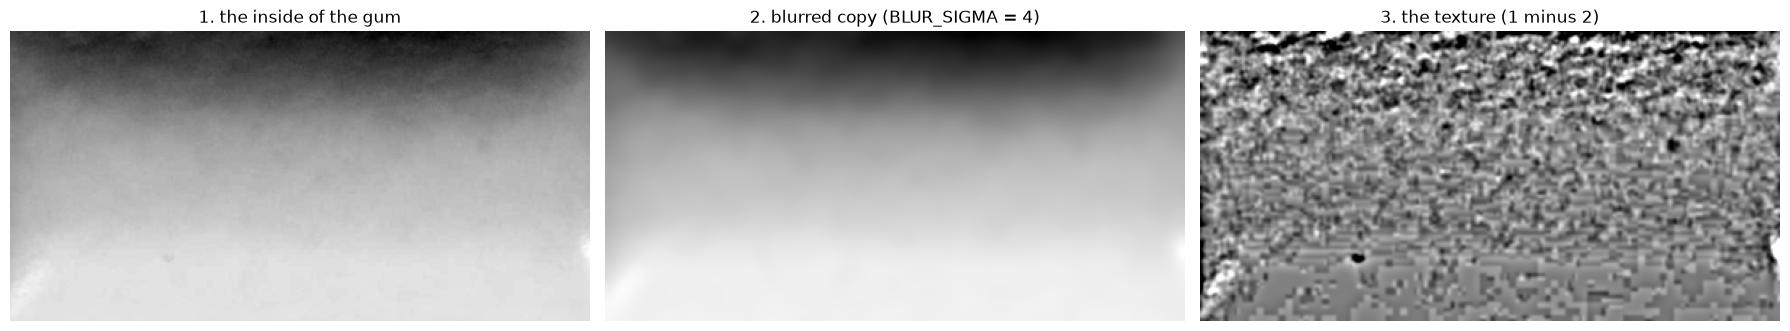

In [14]:
inside_pixels = np.asarray(gray.crop(inside).resize(TEXTURE_SIZE, Image.BILINEAR), dtype=float)
blurred = ndimage.gaussian_filter(inside_pixels, BLUR_SIGMA)
texture = gum_texture(gray, inside, size=TEXTURE_SIZE, blur_sigma=BLUR_SIGMA)

fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
axes[0].imshow(inside_pixels, cmap="gray")
axes[0].set_title("1. the inside of the gum")
axes[1].imshow(blurred, cmap="gray")
axes[1].set_title(f"2. blurred copy (BLUR_SIGMA = {BLUR_SIGMA})")
axes[2].imshow(texture, cmap="gray", vmin=-3, vmax=3)
axes[2].set_title("3. the texture (1 minus 2)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

> **What we see:** the light and shadow (dark at the top, bright at the bottom) are gone in the texture, and the small marks stand out. In the smooth, bright part at the bottom you can also see small square blocks. They come from the JPEG compression of the photo file, not from the gum. The scores in Step 5 show that they do not make two different gums look alike.

## Step 3: Quick Search Over All Pairs

### Make the Texture of Every Photo

> We make the texture of all photos, normal and defect, and keep them in memory as one big array: one 200 x 400 texture per photo.

In [15]:
textures = []
for rel_path, box in tqdm(zip(photos["image"], boxes), total=n_photos, desc="Making the textures"):
    gray = Image.open(os.path.join(RAW_DIR, rel_path)).convert("L")
    textures.append(gum_texture(gray, inner_box(box, margin=INNER_MARGIN), size=TEXTURE_SIZE, blur_sigma=BLUR_SIGMA))
textures = np.stack(textures)
print("Texture array (photos, height, width):", textures.shape)

Making the textures: 100%|██████████| 603/603 [00:06<00:00, 95.16it/s] 


Texture array (photos, height, width): (603, 200, 400)


### Quick Similarity of All Pairs

> Comparing every pair carefully would take hours: 603 photos make 603 x 602 / 2 = 181,503 pairs. So we first compare all pairs in a quick, rough way:
>
> - each texture is made 4 times smaller (`QUICK_BLOCK`), which also makes a small shift matter less,
> - the similarity of all pairs is computed at once, as one big table (`quick`). It is the same correlation as in `similarity()`, but without moving or turning.
>
> Then each photo keeps its `TOP_K` most similar photos. We also add each photo together with the next photo in its folder, because a second photo of the same gum is usually taken right after the first. Only these **candidate pairs** go to the careful comparison.

In [16]:
rows_small, cols_small = TEXTURE_SIZE[1] // QUICK_BLOCK, TEXTURE_SIZE[0] // QUICK_BLOCK
small = textures.reshape(n_photos, rows_small, QUICK_BLOCK, cols_small, QUICK_BLOCK).mean(axis=(2, 4))
small = small.reshape(n_photos, -1)
small = (small - small.mean(axis=1, keepdims=True)) / small.std(axis=1, keepdims=True)
quick = small @ small.T / small.shape[1]
np.fill_diagonal(quick, -np.inf)   # a photo is never compared with itself

candidates = set()
for i in range(n_photos):
    for j in np.argsort(-quick[i])[:TOP_K]:
        candidates.add((min(i, int(j)), max(i, int(j))))
n_from_quick = len(candidates)

in_order = photos.sort_values("image").index.tolist()
folder = photos["image"].map(os.path.dirname)
for i, j in zip(in_order[:-1], in_order[1:]):
    if folder[i] == folder[j]:
        candidates.add((min(i, j), max(i, j)))

print(f"All possible pairs: {n_photos * (n_photos - 1) // 2:,}")
print(f"Candidate pairs from the quick search: {n_from_quick:,}")
print(f"Candidate pairs after adding each photo + the next photo: {len(candidates):,}")

All possible pairs: 181,503
Candidate pairs from the quick search: 2,918
Candidate pairs after adding each photo + the next photo: 3,491


## Step 4: Careful Comparison

### Compare Each Candidate Pair

> For every candidate pair, `similarity()` turns, moves and compares the two textures (see Functions). This takes a few minutes. The table shows the 10 pairs with the highest score. `quick` is the score from the quick search, `score` the careful score.

In [17]:
rows = []
for i, j in tqdm(sorted(candidates), desc="Comparing candidate pairs"):
    rows.append({"photo_a": photos.at[i, "image"], "photo_b": photos.at[j, "image"],
                "quick": quick[i, j], "score": similarity(textures[i], textures[j], angles=ANGLES, edge=EDGE)})
pairs = pd.DataFrame(rows).sort_values("score", ascending=False, ignore_index=True)

top_ten = pairs.head(10).copy()
top_ten[["photo_a", "photo_b"]] = top_ten[["photo_a", "photo_b"]].map(short_name)
top_ten.round(3)

Comparing candidate pairs: 100%|██████████| 3491/3491 [03:38<00:00, 15.99it/s]


,photo_a,photo_b,quick,score
0,Normal/215.JPG,Normal/216.JPG,0.517,0.727
1,Normal/500.JPG,Normal/501.JPG,0.871,0.707
2,Normal/112.JPG,Normal/113.JPG,0.842,0.677
3,Normal/264.JPG,Normal/265.JPG,0.823,0.668
4,Normal/350.JPG,Normal/351.JPG,0.802,0.637
5,Normal/299.JPG,Normal/300.JPG,0.812,0.569
6,Anomaly/040.JPG,Anomaly/049.JPG,0.250,0.210
7,Anomaly/075.JPG,Anomaly/092.JPG,0.130,0.175
8,Anomaly/050.JPG,Anomaly/060.JPG,0.121,0.164
9,Anomaly/045.JPG,Anomaly/046.JPG,0.165,0.157


## Step 5: Choose the Limit

### Where Do the Scores Jump?

> If some photos show the same gum, their scores should be much higher than all other scores, with an empty gap in between. We look for the biggest jump between two scores that follow each other in the sorted list (the top 50 are enough), and put the limit `SAME_GUM_LIMIT` in the middle of that jump.
>
> The histogram shows all careful scores. The count axis is logarithmic (1, 10, 100, ...), so a bar with only 1 pair is still visible. The red line is the limit.

Biggest jump: from 0.569 down to 0.210
SAME_GUM_LIMIT (middle of the jump): 0.39
Pairs above the limit: 6 | pairs below: 3,485
Median score of all candidate pairs: 0.052


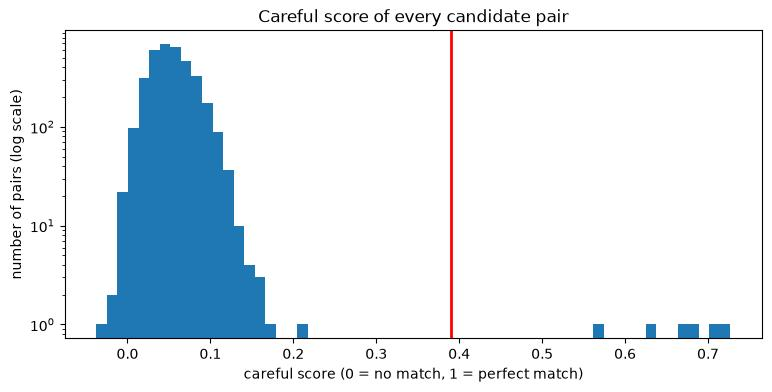

In [18]:
top_scores = pairs["score"].head(50).to_numpy()
jumps = top_scores[:-1] - top_scores[1:]
biggest = int(jumps.argmax())
lowest_match, highest_other = top_scores[biggest], top_scores[biggest + 1]
SAME_GUM_LIMIT = round(float(lowest_match + highest_other) / 2, 2)

print(f"Biggest jump: from {lowest_match:.3f} down to {highest_other:.3f}")
print(f"SAME_GUM_LIMIT (middle of the jump): {SAME_GUM_LIMIT}")
print(f"Pairs above the limit: {(pairs['score'] > SAME_GUM_LIMIT).sum()} | pairs below: {(pairs['score'] <= SAME_GUM_LIMIT).sum():,}")
print(f"Median score of all candidate pairs: {pairs['score'].median():.3f}")

plt.figure(figsize=(9, 4))
plt.hist(pairs["score"], bins=60)
plt.axvline(SAME_GUM_LIMIT, color="red", linewidth=2)
plt.yscale("log")
plt.xlabel("careful score (0 = no match, 1 = perfect match)")
plt.ylabel("number of pairs (log scale)")
plt.title("Careful score of every candidate pair")
plt.show()

> **What we see:** almost all pairs score close to 0 (median 0.05). Then there is a big empty gap, and only 6 pairs are far above it, between 0.569 and 0.727. The jump goes from 0.569 down to 0.210, so the limit is 0.39.

### Did the Quick Search Miss Anything?

> A pair that the quick search did not keep was never compared carefully. So we look at how the quick search ranked each pair above the limit: rank 1 means the partner was the most similar of all other photos. The quick search kept the top `TOP_K` = 5.

In [19]:
index_of = {rel_path: i for i, rel_path in photos["image"].items()}
found = pairs[pairs["score"] > SAME_GUM_LIMIT].copy()
found["rank of b for a"] = [quick_rank(quick, i=index_of[a], j=index_of[b]) for a, b in zip(found["photo_a"], found["photo_b"])]
found["rank of a for b"] = [quick_rank(quick, i=index_of[b], j=index_of[a]) for a, b in zip(found["photo_a"], found["photo_b"])]

show = found.copy()
show[["photo_a", "photo_b"]] = show[["photo_a", "photo_b"]].map(short_name)
show.round(3)

,photo_a,photo_b,quick,score,rank of b for a,rank of a for b
0,Normal/215.JPG,Normal/216.JPG,0.517,0.727,1,1
1,Normal/500.JPG,Normal/501.JPG,0.871,0.707,1,1
2,Normal/112.JPG,Normal/113.JPG,0.842,0.677,1,1
3,Normal/264.JPG,Normal/265.JPG,0.823,0.668,1,1
4,Normal/350.JPG,Normal/351.JPG,0.802,0.637,1,1
5,Normal/299.JPG,Normal/300.JPG,0.812,0.569,1,1


> **What we see:** for every pair, both photos ranked each other as number 1 in the quick search. They would have been found even if each photo had kept only its single most similar photo. So keeping the top 5 leaves plenty of room, and the quick search does not miss pairs like these.

## Step 6: Look at the Pairs

### The Pairs Above the Limit

> A score is only a number, so we also look at the photos ourselves.

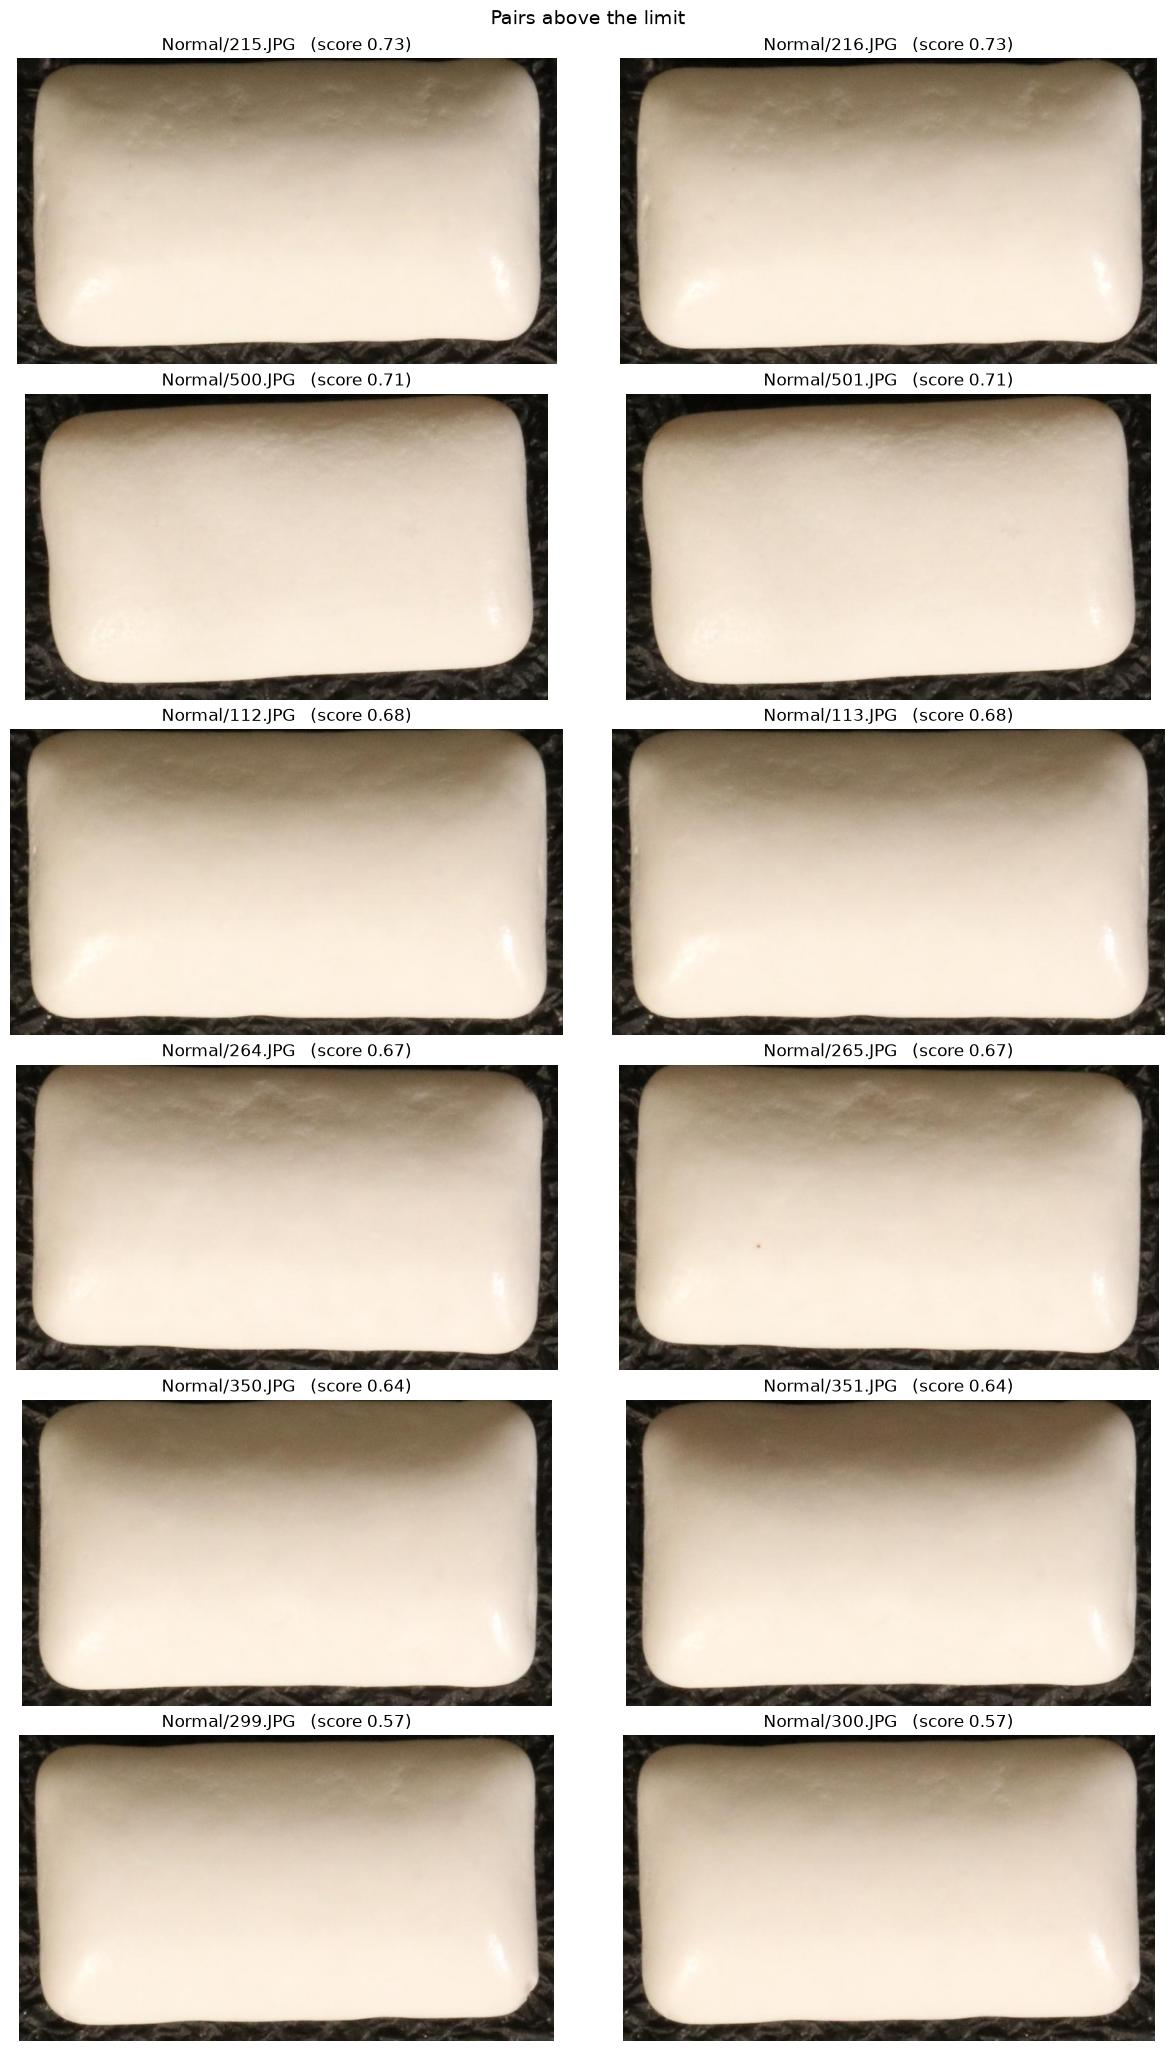

In [20]:
show_pairs(found, title="Pairs above the limit", scale=FIND_SCALE, brightness=GUM_BRIGHTNESS)

> **What we see:** in each pair, the same small bumps, ridges and marks are at the same places. These are the same gums, photographed twice. All of them are normal photos, and the two file numbers of each pair follow each other (like 112 and 113), so the second photo was taken right after the first.

### The Highest Pairs Below the Limit

> To compare: the 3 most similar pairs that are **not** above the limit.

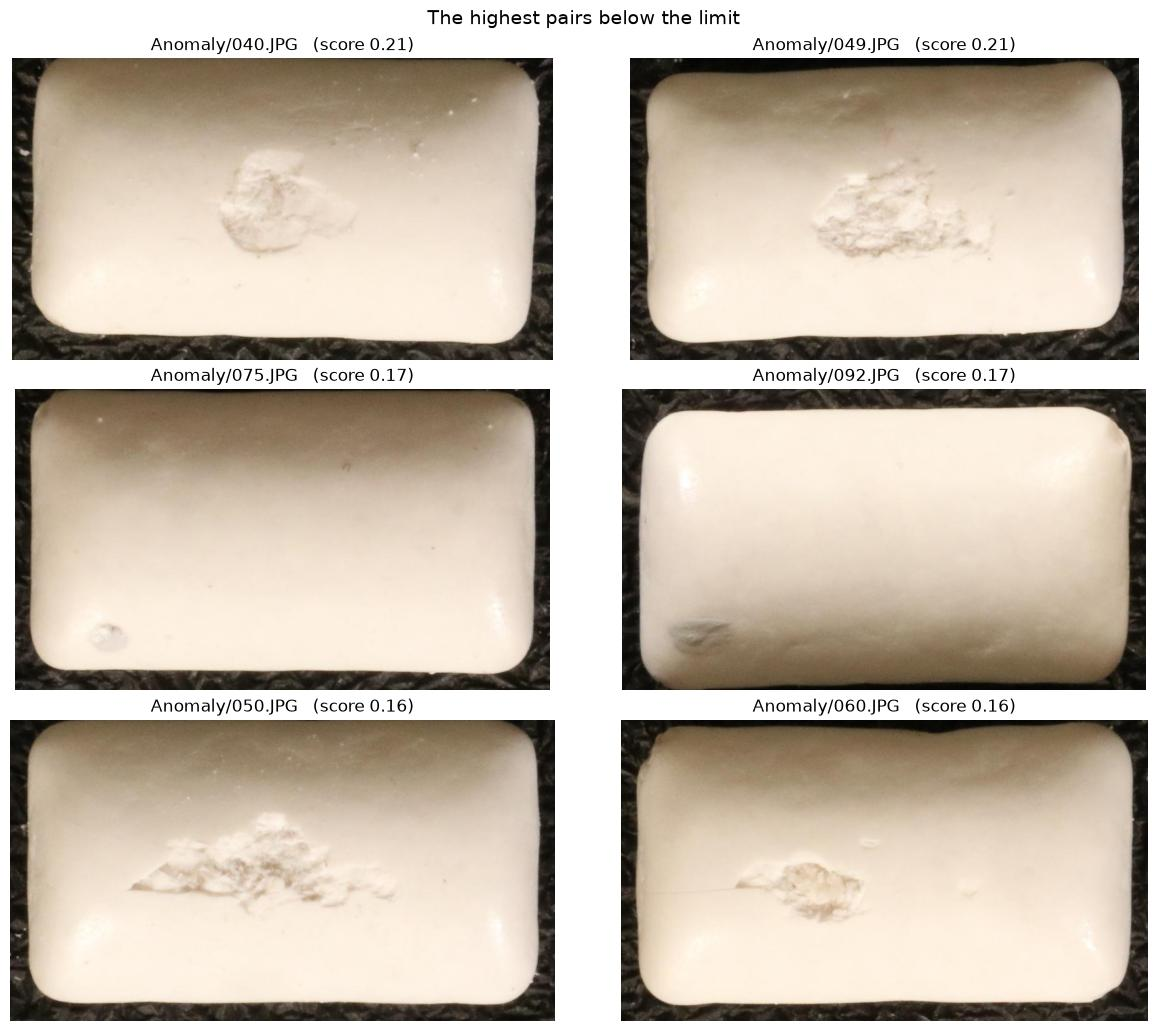

In [21]:
show_pairs(pairs[pairs["score"] <= SAME_GUM_LIMIT].head(3), title="The highest pairs below the limit",
            scale=FIND_SCALE, brightness=GUM_BRIGHTNESS)

> **What we see:** these are clearly different gums: the defects have different shapes and sizes, and the outlines and surface marks of the gums do not match. Their scores are only a little higher than the rest, because defects have strong edges, and strong edges at a similar place look a little alike.

## Step 7: Decide Which Photos to Leave Out

### Make Groups and Choose

> If photo A matches B, and B matches C, all three show the same gum. `connected_components()` joins pairs that share a photo into one **group**.
>
> In each group we **keep** the photo with the lowest file number (the first one taken) and **leave out** the others. A photo that is left out is not used for training, validation or testing, so the same gum can never be in two parts of a split.
>
> This is a preview of the file before it is saved:
>
> - `group`: the number of the group
> - `image`: the photo
> - `is_defect`: `True` for a defect photo
> - `keep`: `True` for the photo we keep, `False` for the photo we leave out
> - `same_gum_as`: for a photo we leave out, the photo we keep of the same gum
> - `score`: the careful score between this photo and the photo we keep, rounded to 3 decimals so the file is exactly the same on every computer

In [22]:
a_index = found["photo_a"].map(index_of).to_numpy()
b_index = found["photo_b"].map(index_of).to_numpy()
graph = coo_matrix((np.ones(len(found)), (a_index, b_index)), shape=(n_photos, n_photos))
n_groups, group_of_photo = connected_components(graph, directed=False)

in_a_pair = sorted(set(a_index) | set(b_index))
same_gum = pd.DataFrame({"image": photos.loc[in_a_pair, "image"].to_numpy(),
                        "is_defect": photos.loc[in_a_pair, "is_defect"].to_numpy(),
                        "component": group_of_photo[in_a_pair]})
same_gum = same_gum.sort_values("image", ignore_index=True)
same_gum["group"] = same_gum.groupby("component", sort=False).ngroup() + 1
same_gum = same_gum.sort_values(["group", "image"], ignore_index=True)
same_gum["keep"] = ~same_gum.duplicated("group")
kept_photo = same_gum[same_gum["keep"]].set_index("group")["image"]
same_gum["same_gum_as"] = same_gum["group"].map(kept_photo).where(~same_gum["keep"], "")

pair_score = {frozenset([a, b]): s for a, b, s in zip(found["photo_a"], found["photo_b"], found["score"])}
same_gum["score"] = [pair_score.get(frozenset([image, other]), np.nan) if other else np.nan
                    for image, other in zip(same_gum["image"], same_gum["same_gum_as"])]
same_gum["score"] = same_gum["score"].round(3)
same_gum = same_gum[["group", "image", "is_defect", "keep", "same_gum_as", "score"]]

left_out = same_gum[~same_gum["keep"]]
print(f"Groups: {same_gum['group'].nunique()} | photos in the groups: {len(same_gum)}")
print(f"Photos to leave out: {len(left_out)} ({(~left_out['is_defect']).sum()} normal, {left_out['is_defect'].sum()} defect)")
same_gum.round(3)

Groups: 6 | photos in the groups: 12
Photos to leave out: 6 (6 normal, 0 defect)


,group,image,is_defect,keep,same_gum_as,score
0,1,chewinggum/Data/Images/Normal/112.JPG,False,True,,NaN
1,1,chewinggum/Data/Images/Normal/113.JPG,False,False,chewinggum/Data/Images/Normal/112.JPG,0.677
2,2,chewinggum/Data/Images/Normal/215.JPG,False,True,,NaN
3,2,chewinggum/Data/Images/Normal/216.JPG,False,False,chewinggum/Data/Images/Normal/215.JPG,0.727
4,3,chewinggum/Data/Images/Normal/264.JPG,False,True,,NaN
5,3,chewinggum/Data/Images/Normal/265.JPG,False,False,chewinggum/Data/Images/Normal/264.JPG,0.668
6,4,chewinggum/Data/Images/Normal/299.JPG,False,True,,NaN
7,4,chewinggum/Data/Images/Normal/300.JPG,False,False,chewinggum/Data/Images/Normal/299.JPG,0.569
8,5,chewinggum/Data/Images/Normal/350.JPG,False,True,,NaN
9,5,chewinggum/Data/Images/Normal/351.JPG,False,False,chewinggum/Data/Images/Normal/350.JPG,0.637


### Save the List

> The folder is made first if it does not exist yet. Notebook 1.3 reads this file and leaves out every photo where `keep` is `False`.

In [23]:
os.makedirs(SPLITS_DIR, exist_ok=True)
same_gum.to_csv(SAME_GUM_FILE, index=False)
print("Saved:", os.path.relpath(SAME_GUM_FILE, ROOT_DIR), f"({len(same_gum)} rows)")

Saved: splits\same_gum_photos.csv (12 rows)


## Summary

> - Comparing all 181,503 pairs carefully would take hours, so a quick search picked 3,491 candidate pairs, and only those were compared carefully.
> - 6 pairs score far above all others (0.569 to 0.727, while the next highest pair scores 0.210). Looking at them confirms that each pair is the same gum, photographed twice.
> - All 6 pairs are normal photos, with file numbers right after each other. No defect photo was photographed twice.
> - We keep the first photo of each pair and leave out the second, so 6 normal photos are not used. `splits/same_gum_photos.csv` lists them.
>
> **Next:** `1.3_split_data.ipynb`